# EDA

En este cuaderno se va a tratar el database para su comprensión y su manipulación en otros cuadernos.

## Carga del CSV

In [156]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt

In [157]:
pd.set_option("display.max_columns", None)
LHC = pd.read_csv("atlas-higgs-challenge-2014-v2.csv", sep=',')


## Análisis del CSV

In [158]:
LHC.head(4)

,EventId,DER_mass_MMC,DER_mass_transverse_met_lep,DER_mass_vis,DER_pt_h,DER_deltaeta_jet_jet,DER_mass_jet_jet,DER_prodeta_jet_jet,DER_deltar_tau_lep,DER_pt_tot,DER_sum_pt,DER_pt_ratio_lep_tau,DER_met_phi_centrality,DER_lep_eta_centrality,PRI_tau_pt,PRI_tau_eta,PRI_tau_phi,PRI_lep_pt,PRI_lep_eta,PRI_lep_phi,PRI_met,PRI_met_phi,PRI_met_sumet,PRI_jet_num,PRI_jet_leading_pt,PRI_jet_leading_eta,PRI_jet_leading_phi,PRI_jet_subleading_pt,PRI_jet_subleading_eta,PRI_jet_subleading_phi,PRI_jet_all_pt,Weight,Label,KaggleSet,KaggleWeight
0,100000,138.470,51.655,97.827,27.980,0.91,124.711,2.666,3.064,41.928,197.760,1.582,1.396,0.2,32.638,1.017,0.381,51.626,2.273,-2.414,16.824,-0.277,258.733,2,67.435,2.150,0.444,46.062,1.24,-2.475,113.497,0.000814,s,t,0.002653
1,100001,160.937,68.768,103.235,48.146,-999.00,-999.000,-999.000,3.473,2.078,125.157,0.879,1.414,-999.0,42.014,2.039,-3.011,36.918,0.501,0.103,44.704,-1.916,164.546,1,46.226,0.725,1.158,-999.000,-999.00,-999.000,46.226,0.681042,b,t,2.233584
2,100002,-999.000,162.172,125.953,35.635,-999.00,-999.000,-999.000,3.148,9.336,197.814,3.776,1.414,-999.0,32.154,-0.705,-2.093,121.409,-0.953,1.052,54.283,-2.186,260.414,1,44.251,2.053,-2.028,-999.000,-999.00,-999.000,44.251,0.715742,b,t,2.347389
3,100003,143.905,81.417,80.943,0.414,-999.00,-999.000,-999.000,3.310,0.414,75.968,2.354,-1.285,-999.0,22.647,-1.655,0.010,53.321,-0.522,-3.100,31.082,0.060,86.062,0,-999.000,-999.000,-999.000,-999.000,-999.00,-999.000,-0.000,1.660654,b,t,5.446378


In [159]:
LHC.info()
# CSV de 818238 datos
# 35 columnas de información de las cuales 3 son string, es decir, contienen información, no valor.

<class 'pandas.DataFrame'>
RangeIndex: 818238 entries, 0 to 818237
Data columns (total 35 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   EventId                      818238 non-null  int64  
 1   DER_mass_MMC                 818238 non-null  float64
 2   DER_mass_transverse_met_lep  818238 non-null  float64
 3   DER_mass_vis                 818238 non-null  float64
 4   DER_pt_h                     818238 non-null  float64
 5   DER_deltaeta_jet_jet         818238 non-null  float64
 6   DER_mass_jet_jet             818238 non-null  float64
 7   DER_prodeta_jet_jet          818238 non-null  float64
 8   DER_deltar_tau_lep           818238 non-null  float64
 9   DER_pt_tot                   818238 non-null  float64
 10  DER_sum_pt                   818238 non-null  float64
 11  DER_pt_ratio_lep_tau         818238 non-null  float64
 12  DER_met_phi_centrality       818238 non-null  float64
 13  DER_lep_et

Se puede apreciar que no existe ningún valor Nan ya que todos tienen la misma cantidad de valores non-null que dimensión tiene el CSV. No obstante, que no haya valor Nan no significa que el CSV esté completo. Vease el apartado **Análisis del valor -999**

In [160]:
# la información de cada columna de tipo string
print(LHC['Label'].unique())
print(LHC['KaggleSet'].unique())

<StringArray>
['s', 'b']
Length: 2, dtype: str
<StringArray>
['t', 'b', 'v', 'u']
Length: 4, dtype: str


### Significado de cada columna:

| Columna | Significado |
| --- | --- |
| EventId | Localizador para cada fila |
| Weight | Peso del evento (que se utiliza para calcular el AMS), normalizado sobre el dataset completo |
| Label | Etiqueta que representa si el evento es s (señal de Higgs) o b (señal de fondo) |
| KaggleSet | Los subconjuntos que se utilizarón en la competición siendo t el subconjunto de entrenamiento, b el subconjunto de validación y v el subconjunto de test final |
| KaggleWeight | Los pesos normalizados de cada subconjunto de KaggleSet |


**PRI (Variables primitivas)**

Son parámetros medidos directamente por el detector. Momentos y energías en GeV, ángulos $\phi$ en radianes, $\eta$ (pseudorapidez) adimensional. Para entender qué es cada cosa es necesario entender cómo surgen. 

En el HCL se coge partículas de hidrógeno sin electrones (es decir, protones) y se las hace chocar hasta detectar esos choques interesantes que generar el bosson de Higgs. Puede emerger de dos forma:
- Fusión de gluones: en el que sale un bosson de Higgs con  o 1 chorro.
- Fusión de bosones vectoriales (VBF): en el que 2 quarks emiten bossones que se fusionan en un Higgs, saliendo los 2 quarks como 2 chorros.

Por tanto la variable PRI_jet_num lo que permite es distinguir el modo de producción del bosson de Higgs.
Por otro lado, el bosson de Higgs tiene una desintegración de 10^(-22)segundos, por lo que la información de su existencia no viene determinada por su detección, sino por la detección de sus desintegraciones. Este bosson de Higgs se desintegra en dos Tau, que a su vez, uno se desintegra en hadrones (PRI_Tau_) y el otro se desintegra en muones o eletrones (PRI_lep). Agrupando la energía transversal total del choque en la variable PRI_met_sumet.

| Columna | Significado |
|---|---|
| PRI_tau_pt | Momento transversal del tau hadrónico |
| PRI_tau_eta | Pseudorapidez del tau hadrónico |
| PRI_tau_phi | Ángulo azimutal del tau hadrónico |
| PRI_lep_pt | Momento transversal del leptón (electrón o muón) |
| PRI_lep_eta | Pseudorapidez del leptón |
| PRI_lep_phi | Ángulo azimutal del leptón |
| PRI_met | Módulo de la energía transversal perdida (la que se llevan los neutrinos) |
| PRI_met_phi | Ángulo azimutal de la energía transversal perdida |
| PRI_met_sumet | Energía transversal total depositada en el detector |
| PRI_jet_num | Número de chorros (0, 1, 2 o 3; el 3 significa "3 o más") |
| PRI_jet_leading_pt | Momento transversal del chorro principal (mayor $p_T$) |
| PRI_jet_leading_eta | Pseudorapidez del chorro principal |
| PRI_jet_leading_phi | Ángulo azimutal del chorro principal |
| PRI_jet_subleading_pt | Momento transversal del segundo chorro |
| PRI_jet_subleading_eta | Pseudorapidez del segundo chorro |
| PRI_jet_subleading_phi | Ángulo azimutal del segundo chorro |
| PRI_jet_all_pt | Suma escalar del $p_T$ de todos los chorros |


**DER (Variables derivadas)**

Calculadas por los físicos a partir de las PRI. Notación: $\vec{p}_T = p_T(\cos\phi, \sin\phi)$ es el momento transversal como vector; $\Delta\phi$ se reduce siempre al intervalo $[-\pi, \pi]$; $j_1$ y $j_2$ son el chorro principal y el segundo chorro. Las masas suponen partículas sin masa ($m \approx 0$).

| Columna | Significado | Cálculo a partir de las PRI |
|---|---|---|
| DER_mass_MMC | Masa estimada del candidato a Higgs | Algoritmo *Missing Mass Calculator*: maximiza una verosimilitud sobre la cinemática de los neutrinos usando tau, leptón y MET. No tiene fórmula cerrada |
| DER_mass_transverse_met_lep | Masa transversal entre leptón y energía perdida | $\sqrt{2\, p_T^{lep}\, E_T^{miss}\,\left(1-\cos(\phi_{lep}-\phi_{met})\right)}$ |
| DER_mass_vis | Masa invariante visible de tau + leptón | $\sqrt{2\, p_T^{\tau}\, p_T^{lep}\,\left(\cosh(\eta_\tau-\eta_{lep})-\cos(\phi_\tau-\phi_{lep})\right)}$ |
| DER_pt_h | $p_T$ del candidato a Higgs | $\lVert \vec{p}_T^{\,\tau}+\vec{p}_T^{\,lep}+\vec{E}_T^{\,miss} \rVert$ |
| DER_deltaeta_jet_jet | Separación en $\eta$ entre los dos chorros | $\lvert \eta_{j_1}-\eta_{j_2} \rvert$ |
| DER_mass_jet_jet | Masa invariante de los dos chorros | $\sqrt{2\, p_T^{j_1}\, p_T^{j_2}\,\left(\cosh(\eta_{j_1}-\eta_{j_2})-\cos(\phi_{j_1}-\phi_{j_2})\right)}$ |
| DER_prodeta_jet_jet | Producto de las $\eta$ de los dos chorros | $\eta_{j_1}\cdot\eta_{j_2}$ |
| DER_deltar_tau_lep | Separación angular entre tau y leptón | $\sqrt{(\eta_\tau-\eta_{lep})^2+(\Delta\phi_{\tau,lep})^2}$ |
| DER_pt_tot | Módulo del $p_T$ total del evento | $\lVert \vec{p}_T^{\,\tau}+\vec{p}_T^{\,lep}+\vec{p}_T^{\,j_1}+\vec{p}_T^{\,j_2}+\vec{E}_T^{\,miss} \rVert$ |
| DER_sum_pt | Suma escalar de momentos transversales | $p_T^{\tau}+p_T^{lep}+$ PRI_jet_all_pt |
| DER_pt_ratio_lep_tau | Cociente de momentos leptón/tau | $p_T^{lep}\,/\,p_T^{\tau}$ |
| DER_met_phi_centrality | Indica si la MET apunta "entre" tau y leptón en $\phi$ (rango $[-\sqrt{2},\sqrt{2}]$) | $\dfrac{A+B}{\sqrt{A^2+B^2}}$, con $s=\operatorname{sgn}(\sin(\phi_\tau-\phi_{lep}))$, $A=s\,\sin(\phi_{met}-\phi_{lep})$, $B=s\,\sin(\phi_\tau-\phi_{met})$ |
| DER_lep_eta_centrality | Indica si el leptón está "entre" los dos chorros en $\eta$ (1 en el centro, $1/e$ en los chorros) | $\exp\!\left[-\dfrac{4}{(\eta_{j_1}-\eta_{j_2})^2}\left(\eta_{lep}-\dfrac{\eta_{j_1}+\eta_{j_2}}{2}\right)^2\right]$ |

### Análisis del valor -999

El significado físico sobre el valore -999 es equivalente a los valores faltantes o Nan. Por ello el el análisis del valor -999 equivale a la limpieza del data set 

In [161]:
print([col for col in LHC.columns if (LHC[col] == -999).any()])
print("\nCantidad de valores -999/Nan:")
print(f"- PRI_jet_leading_pt: {LHC["PRI_jet_leading_pt"].value_counts().get(-999,0)}/{LHC["PRI_jet_leading_pt"].count()} = {(LHC["PRI_jet_leading_pt"].value_counts().get(-999,0)/LHC["PRI_jet_leading_pt"].count()):.1%}")
print(f"- PRI_jet_leading_eta: {LHC["PRI_jet_leading_eta"].value_counts().get(-999,0)}/{LHC["PRI_jet_leading_eta"].count()} = {(LHC["PRI_jet_leading_eta"].value_counts().get(-999,0)/LHC["PRI_jet_leading_eta"].count()):.1%}")
print(f"- PRI_jet_leading_phi: {LHC["PRI_jet_leading_phi"].value_counts().get(-999,0)}/{LHC["PRI_jet_leading_phi"].count()} = {(LHC["PRI_jet_leading_phi"].value_counts().get(-999,0)/LHC["PRI_jet_leading_phi"].count()):.1%}")
print(f"- PRI_jet_subleading_pt: {LHC["PRI_jet_subleading_pt"].value_counts().get(-999,0)}/{LHC["PRI_jet_subleading_pt"].count()} = {(LHC["PRI_jet_subleading_pt"].value_counts().get(-999,0)/LHC["PRI_jet_subleading_pt"].count()):.1%}")
print(f"- PRI_jet_subleading_eta: {LHC["PRI_jet_subleading_eta"].value_counts().get(-999,0)}/{LHC["PRI_jet_subleading_eta"].count()} = {(LHC["PRI_jet_subleading_eta"].value_counts().get(-999,0)/LHC["PRI_jet_subleading_eta"].count()):.1%}")
print(f"- PRI_jet_subleading_phi: {LHC["PRI_jet_subleading_phi"].value_counts().get(-999,0)}/{LHC["PRI_jet_subleading_phi"].count()} = {(LHC["PRI_jet_subleading_phi"].value_counts().get(-999,0)/LHC["PRI_jet_subleading_phi"].count()):.1%}")
print(f"- DER_mass_MMC: {LHC["DER_mass_MMC"].value_counts().get(-999,0)}/{LHC["DER_mass_MMC"].count()} = {(LHC["DER_mass_MMC"].value_counts().get(-999,0)/LHC["DER_mass_MMC"].count()):.1%}")
print(f"- DER_deltaeta_jet_jet: {LHC["DER_deltaeta_jet_jet"].value_counts().get(-999,0)}/{LHC["DER_deltaeta_jet_jet"].count()} = {(LHC["DER_deltaeta_jet_jet"].value_counts().get(-999,0)/LHC["DER_deltaeta_jet_jet"].count()):.1%}")
print(f"- DER_mass_jet_jet: {LHC["DER_mass_jet_jet"].value_counts().get(-999,0)}/{LHC["DER_mass_jet_jet"].count()} = {(LHC["DER_mass_jet_jet"].value_counts().get(-999,0)/LHC["DER_mass_jet_jet"].count()):.1%}")
print(f"- DER_prodeta_jet_jet: {LHC["DER_prodeta_jet_jet"].value_counts().get(-999,0)}/{LHC["DER_prodeta_jet_jet"].count()} = {(LHC["DER_prodeta_jet_jet"].value_counts().get(-999,0)/LHC["DER_prodeta_jet_jet"].count()):.1%}")
print(f"- DER_lep_eta_centrality: {LHC["DER_lep_eta_centrality"].value_counts().get(-999,0)}/{LHC["DER_lep_eta_centrality"].count()} = {(LHC["DER_lep_eta_centrality"].value_counts().get(-999,0)/LHC["DER_lep_eta_centrality"].count()):.1%}")


['DER_mass_MMC', 'DER_deltaeta_jet_jet', 'DER_mass_jet_jet', 'DER_prodeta_jet_jet', 'DER_lep_eta_centrality', 'PRI_jet_leading_pt', 'PRI_jet_leading_eta', 'PRI_jet_leading_phi', 'PRI_jet_subleading_pt', 'PRI_jet_subleading_eta', 'PRI_jet_subleading_phi']

Cantidad de valores -999/Nan:
- PRI_jet_leading_pt: 327371/818238 = 40.0%
- PRI_jet_leading_eta: 327371/818238 = 40.0%
- PRI_jet_leading_phi: 327371/818238 = 40.0%
- PRI_jet_subleading_pt: 580253/818238 = 70.9%
- PRI_jet_subleading_eta: 580253/818238 = 70.9%
- PRI_jet_subleading_phi: 580253/818238 = 70.9%
- DER_mass_MMC: 124602/818238 = 15.2%
- DER_deltaeta_jet_jet: 580253/818238 = 70.9%
- DER_mass_jet_jet: 580253/818238 = 70.9%
- DER_prodeta_jet_jet: 580253/818238 = 70.9%
- DER_lep_eta_centrality: 580253/818238 = 70.9%


El análisis de estos valores -999 tiene todo el sentido, si no existe primer chorro, no existe segundo. Proporción de CSV con 0 chorros 40%, 1 chorro 30% y 2 chorros 30%. Por tanto la cantidad de boson de Higgs que proceden de la fusión de bosones vectoriales son el 30% del CSV (2 chorros), y de la fusión de gluones es el 70%. Por tanto no se va a tratar como valores faltantes, sino como información clasificatoria, que simplemente el MLP no tendrá que utilizar.

Con esa misma argumentación, la proporción de las variables DER tienen sentido, ya que no se podrá calcular la misma cantidad de fórmulas que necesiten información de los dos chorros

### Reestructuración del CSV

No obstante, lo que sí que hay que tener en cuenta es el objetivo de este proyecto, es decir, si es posible conseguir un buen AMS usando solo los PRI o si son necesarios los DER. Para el procedimiento del MLP se necesitan tres conjuntos, uno para entrenar, otro para ajustar hiperparámetros y otro para hacer el test final. Para ello se utilizarán las etiquetas de KaggleSet que ya los diferencia. Además, tenemos que tener en cuenta que cada uno de estos grupos se tendrán que diferencias en la comparación que se quiere hacer, es decir, por un lado los PRI y por otro lado los PRI + DER.

In [162]:
Entrenamiento = LHC[LHC["KaggleSet"] == "t"]
Ajuste = LHC[LHC["KaggleSet"] == "b"]
Test = LHC[LHC["KaggleSet"] == "v"]

Antes de dividir entre los subconjuntos PRI y DER + PRI se va estandarizar los valores de cada subconjunto y sustitutyendo los valores -999 por cero. Para poder hacer la estandarización de una manera más simple, se transformarán todos los valores de -999 en NaN. Se van a estandarizar los tres conjuntos respecto de la media y desviación típica del conjunto t.

In [163]:
Entrenamiento = Entrenamiento.replace(-999, np.nan)
Ajuste = Ajuste.replace(-999, np.nan)
Test = Test.replace(-999, np.nan)

In [164]:
scaler = StandardScaler()

variables = ["DER_mass_MMC", "DER_mass_transverse_met_lep", "DER_mass_vis", "DER_pt_h", "DER_deltaeta_jet_jet", "DER_mass_jet_jet", "DER_prodeta_jet_jet", "DER_deltar_tau_lep", "DER_pt_tot", "DER_sum_pt", "DER_pt_ratio_lep_tau", "DER_met_phi_centrality", "DER_lep_eta_centrality", "PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met",	"PRI_met_phi","PRI_met_sumet","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt","PRI_jet_subleading_eta","PRI_jet_subleading_phi","PRI_jet_all_pt"]

Entrenamiento[variables] = scaler.fit_transform(Entrenamiento[variables])
Ajuste[variables] = scaler.transform(Ajuste[variables])
Test[variables] = scaler.transform(Test[variables])

Entrenamiento = Entrenamiento.replace(np.nan, 0)
Ajuste = Ajuste.replace(np.nan, 0)
Test = Test.replace(np.nan, 0)

Dividimos los subconjuntos de Entrenamiento, Ajusta y Test en PRI y PRI + DER.

In [165]:
Entrenamiento_DER = Entrenamiento.drop(columns=["EventId", "Weight", "KaggleSet", "Label", "KaggleWeight"])
Ajuste_DER = Ajuste.drop(columns=["EventId", "Weight", "KaggleSet", "Label", "KaggleWeight"])
Test_DER = Test.drop(columns=["EventId", "Weight", "KaggleSet", "Label", "KaggleWeight"])

# Se elimina la columna Weight ya que representa los pesos normalizados respecto a todo el conjunto LHC. Ahora los pesos normalizados están en la variable KaggleWeight.
# Se elimina la columna KaggleSet porque ya están dividos y pasa a ser una columna con contenido irrelevante.
# Se elimina la columna Label para que los grupos solo tengan valores numéricos, creando una base de datos de los label respecto de cada eventId
# Se van a descartar los valores del grupo u ya que no se requiere de ningún conjunto más para desarrollar el proyecto.

In [ ]:
Entrenamiento_PRI = Entrenamiento_DER[["PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met","PRI_met_phi","PRI_met_sumet","PRI_jet_num","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt", "PRI_jet_subleading_eta","PRI_jet_subleading_phi","PRI_jet_all_pt"]].copy().reset_index(drop=True)
Ajuste_PRI = Ajuste_DER[["PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met",	"PRI_met_phi","PRI_met_sumet","PRI_jet_num","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt", "PRI_jet_subleading_eta",	"PRI_jet_subleading_phi","PRI_jet_all_pt"]].copy().reset_index(drop=True)
Test_PRI = Test_DER[["PRI_tau_pt", "PRI_tau_eta", "PRI_tau_phi","PRI_lep_pt","PRI_lep_eta","PRI_lep_phi","PRI_met",	"PRI_met_phi","PRI_met_sumet","PRI_jet_num","PRI_jet_leading_pt","PRI_jet_leading_eta","PRI_jet_leading_phi","PRI_jet_subleading_pt", "PRI_jet_subleading_eta",	"PRI_jet_subleading_phi","PRI_jet_all_pt"]].copy().reset_index(drop=True)

ENTRENAMIENTO
Cantidad de valores:250000
Suma total de pesos:125530.31906160462
Label
b    164333
s     85667
Name: count, dtype: int64

AJUSTE
Cantidad de valores:100000
Suma total de pesos:50548.160673219114
Label
b    65975
s    34025
Name: count, dtype: int64

TEST
Cantidad de valores:450000
Suma total de pesos:226424.1456505556
Label
b    296317
s    153683
Name: count, dtype: int64



In [168]:
Entrenamiento.to_csv("Entrenamiento.csv", index=False)
Ajuste.to_csv("Ajuste.csv", index=False)
Test.to_csv("Test.csv", index=False)

In [169]:
# Se tiene en cuenta la cantidad de cantidad de valores, suma total de pesos y la cantidad de valores de bosson de Higgs (b) y valores de fondo (s).
print(f"ENTRENAMIENTO\nCantidad de valores:{len(Entrenamiento)}\nSuma total de pesos:{Entrenamiento["Weight"].sum()}\n{Entrenamiento["Label"].value_counts()}\n")  
print(f"AJUSTE\nCantidad de valores:{len(Ajuste)}\nSuma total de pesos:{Ajuste["Weight"].sum()}\n{Ajuste["Label"].value_counts()}\n")
print(f"TEST\nCantidad de valores:{len(Test)}\nSuma total de pesos:{Test["Weight"].sum()}\n{Test["Label"].value_counts()}\n")

ENTRENAMIENTO
Cantidad de valores:250000
Suma total de pesos:125530.31906160462
Label
b    164333
s     85667
Name: count, dtype: int64

AJUSTE
Cantidad de valores:100000
Suma total de pesos:50548.160673219114
Label
b    65975
s    34025
Name: count, dtype: int64

TEST
Cantidad de valores:450000
Suma total de pesos:226424.1456505556
Label
b    296317
s    153683
Name: count, dtype: int64



**Aviso**: se deja pendiente para el análisis de datos que no se ha implementado el logaritmo a ninguna variable con cola larga. Y que su implementación podría mejorar el resultado.

### Correlaciones de datos

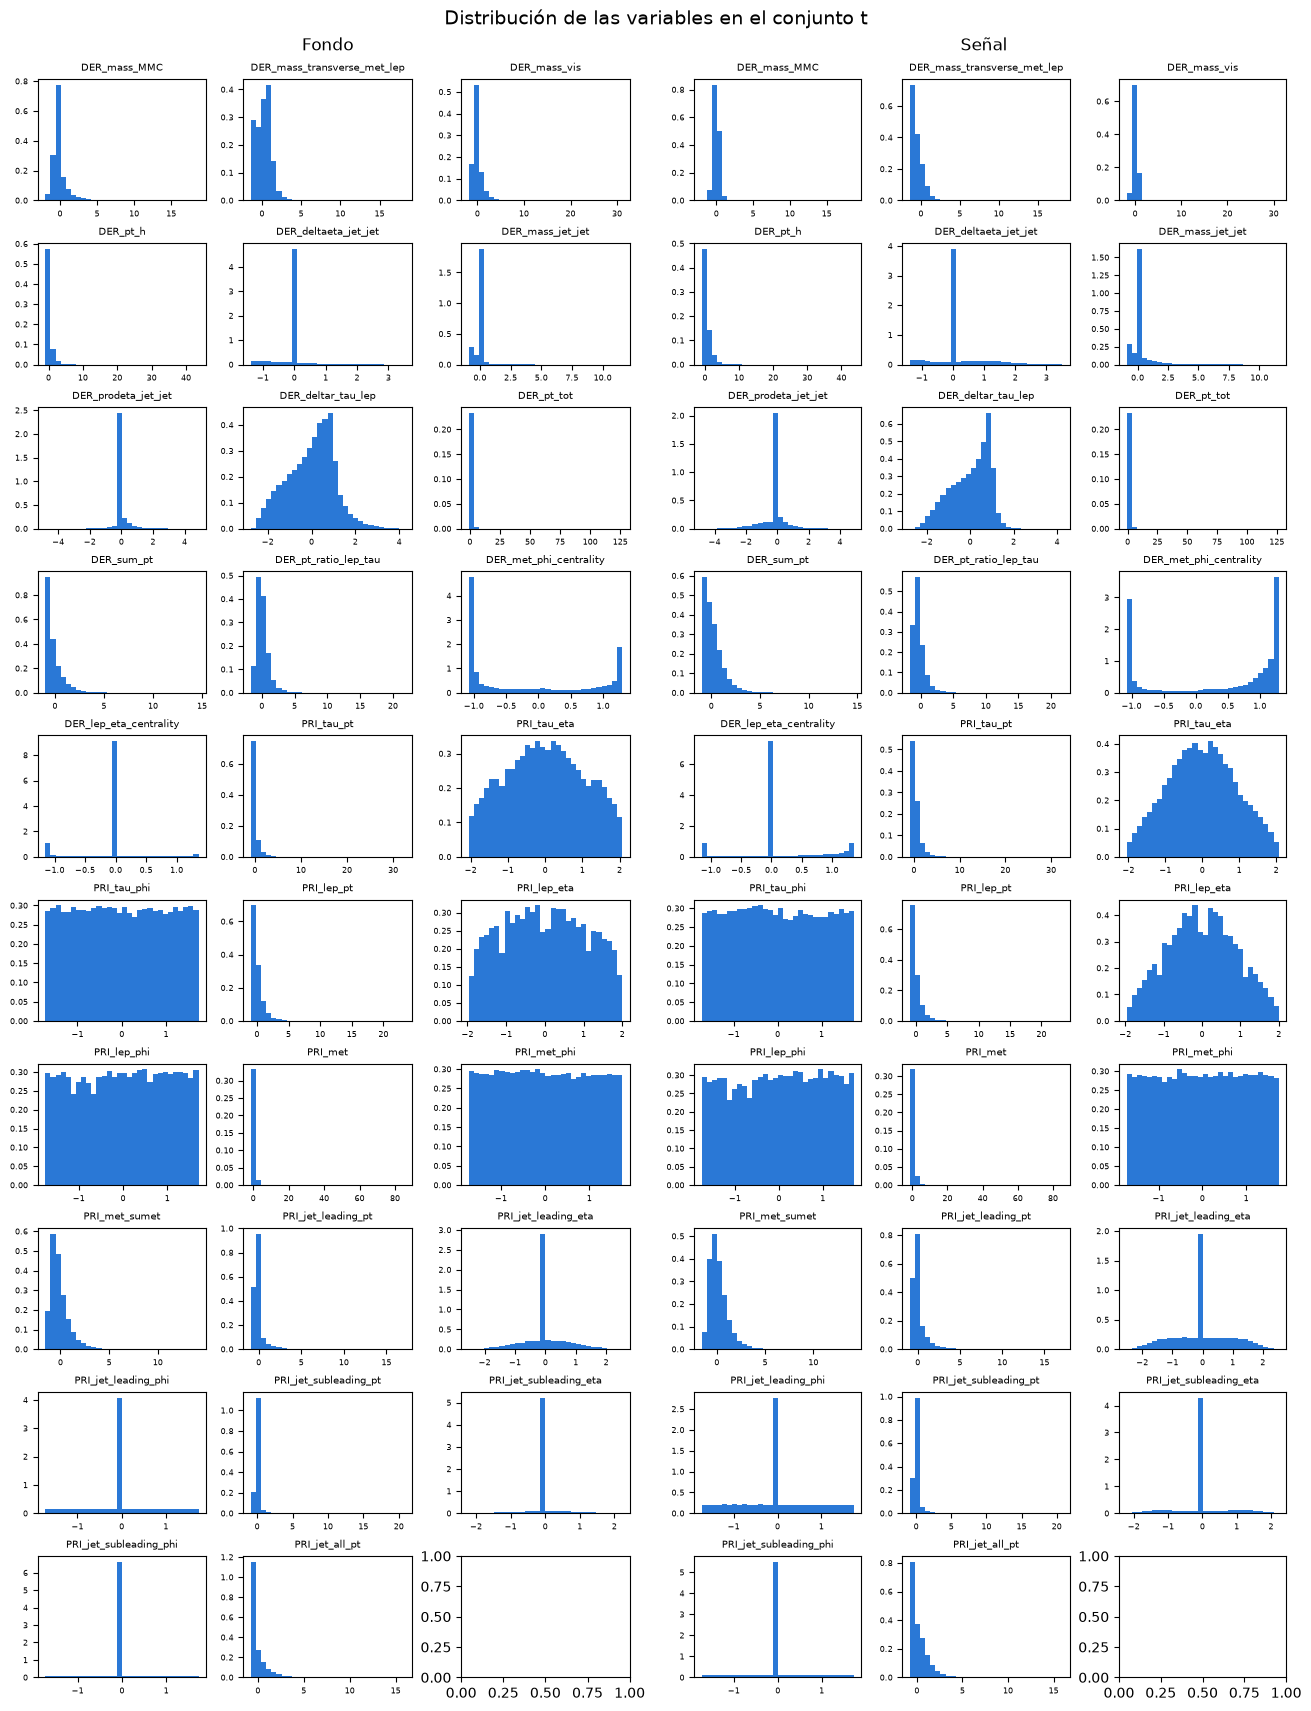

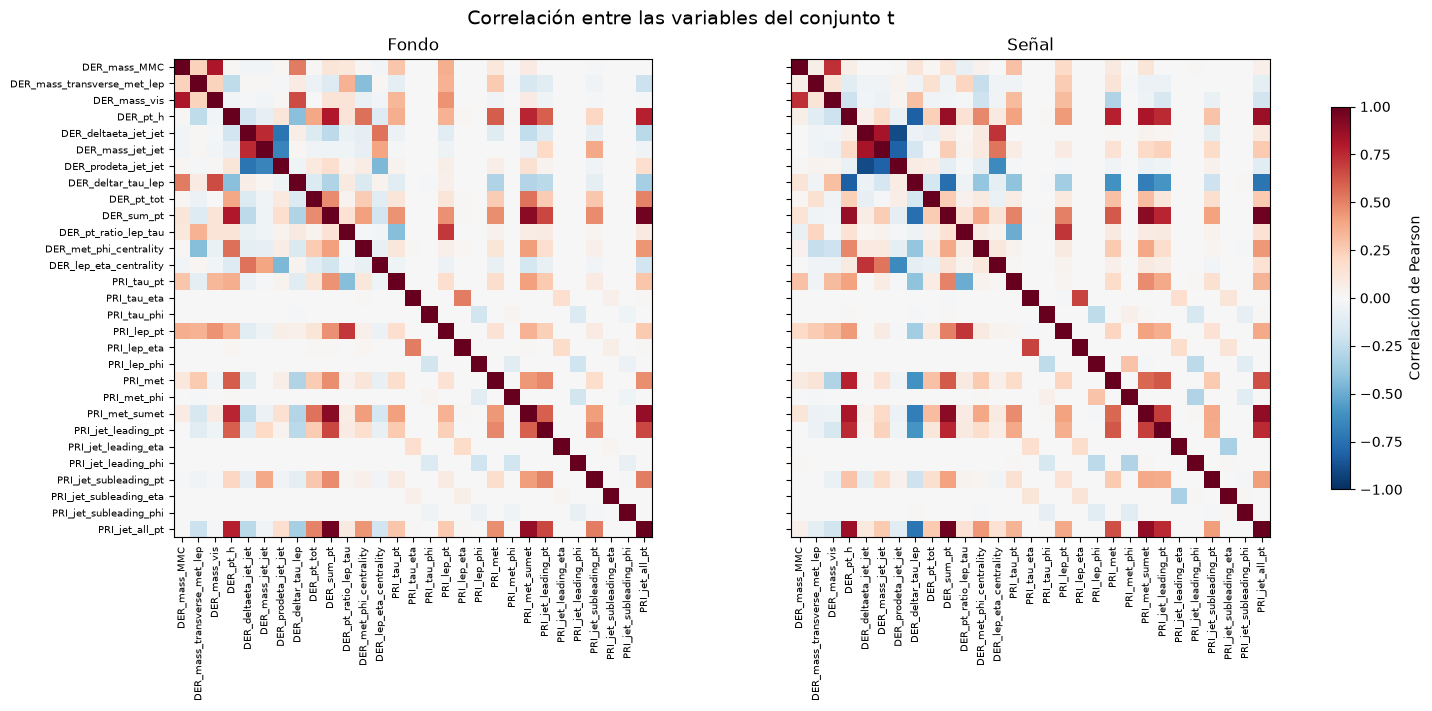

In [170]:
columna = "Label"
clases = ["b", "s"]
nombres = {"b": "Fondo", "s": "Señal"}

todos = Entrenamiento[variables]
datos_por_clase = {clase: todos[Entrenamiento[columna] == clase] for clase in clases}

# Histogramas
filas, columnas = 10, 3
fig = plt.figure(figsize=(13, 17), layout="constrained")
subfiguras = fig.subfigures(1, 2)

for subfigura, clase in zip(subfiguras, clases):
    subfigura.suptitle(nombres[clase], fontsize=12)
    axes = subfigura.subplots(filas, columnas).ravel()

    for ax, variable in zip(axes, variables):
        intervalos = np.histogram_bin_edges(todos[variable].dropna(), bins=30)
        ax.hist(datos_por_clase[clase][variable].dropna(), bins=intervalos,
                density=True, color="#2a78d6")
        ax.set_title(variable, fontsize=7)
        ax.tick_params(labelsize=6)

fig.suptitle("Distribución de las variables en el conjunto t", fontsize=14)
plt.show()

# Mapas de calor
fig, axes = plt.subplots(1, 2, figsize=(15, 7), layout="constrained")

for ax, clase in zip(axes, clases):
    corr = datos_por_clase[clase].corr()
    imagen = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
    ax.set_xticks(range(len(corr)), corr.columns, rotation=90, fontsize=7)
    ax.set_yticks(range(len(corr)), corr.columns, fontsize=7)
    ax.set_title(nombres[clase])

axes[1].set_yticks(range(len(corr)), [])
fig.colorbar(imagen, ax=axes, label="Correlación de Pearson", shrink=0.8)
fig.suptitle("Correlación entre las variables del conjunto t", fontsize=14)
plt.show()

Aquí se confirma las relación directa o correlación entre las PRI cuyos valores (sobre todo nulos) determinan las DER que se calculan con dichos valores.